### **The RemoveMessage Class**

#### Set the OpenAI API Key as an Environment Variable

In [1]:
%load_ext dotenv
%dotenv
%load_ext mypy_ipython

#### Import Relevant Classes and Functions

In [2]:
from langgraph.graph import START, END, StateGraph, add_messages, MessagesState
from typing_extensions import TypedDict
from langchain_openai.chat_models import ChatOpenAI
from langchain_core.messages import HumanMessage, BaseMessage, AIMessage, RemoveMessage
from collections.abc import Sequence
from typing import Literal, Annotated

#### Get Familiar with RemoveMessage

In [3]:
my_list = add_messages([AIMessage("What is your question?"),
                        HumanMessage("Who played in the FIFA World Cup 2014 final?"),
                        AIMessage("Argentina played against Germany..."),
                        AIMessage("Would you like to ask one more question?"),
                        HumanMessage("yes"),
                        AIMessage("What is your question?"),
                        HumanMessage("What about 2018?"),
                        AIMessage("France played against Croatia..."),
                        AIMessage("Would you like to ask one more question?")],
                        [HumanMessage("yes")])

In [4]:
my_list[:-5]

[AIMessage(content='What is your question?', additional_kwargs={}, response_metadata={}, id='d0e43015-0686-4241-9ca4-99b508d058c2', tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content='Who played in the FIFA World Cup 2014 final?', additional_kwargs={}, response_metadata={}, id='d356f3fc-d162-4a35-bcd4-1b2fec9f9bd9'),
 AIMessage(content='Argentina played against Germany...', additional_kwargs={}, response_metadata={}, id='a2c158c7-da47-4e57-8d99-8f9d9da0159d', tool_calls=[], invalid_tool_calls=[]),
 AIMessage(content='Would you like to ask one more question?', additional_kwargs={}, response_metadata={}, id='4c28348f-8646-4c7c-b34f-f71e79991687', tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content='yes', additional_kwargs={}, response_metadata={}, id='9a21c00e-54d2-4dc8-a79e-276211d34b32')]

In [5]:
remove_messages = [RemoveMessage(id = i.id) for i in my_list[:-5]]

In [6]:
remove_messages

[RemoveMessage(content='', additional_kwargs={}, response_metadata={}, id='d0e43015-0686-4241-9ca4-99b508d058c2'),
 RemoveMessage(content='', additional_kwargs={}, response_metadata={}, id='d356f3fc-d162-4a35-bcd4-1b2fec9f9bd9'),
 RemoveMessage(content='', additional_kwargs={}, response_metadata={}, id='a2c158c7-da47-4e57-8d99-8f9d9da0159d'),
 RemoveMessage(content='', additional_kwargs={}, response_metadata={}, id='4c28348f-8646-4c7c-b34f-f71e79991687'),
 RemoveMessage(content='', additional_kwargs={}, response_metadata={}, id='9a21c00e-54d2-4dc8-a79e-276211d34b32')]

In [7]:
add_messages(my_list, remove_messages)

[AIMessage(content='What is your question?', additional_kwargs={}, response_metadata={}, id='e504dedd-937b-4672-984e-7604fa96ecbf', tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content='What about 2018?', additional_kwargs={}, response_metadata={}, id='96232982-4e80-40d4-ac6a-b9427b90930e'),
 AIMessage(content='France played against Croatia...', additional_kwargs={}, response_metadata={}, id='b9d4c8e3-2bc2-4224-8972-1cbf1ee315df', tool_calls=[], invalid_tool_calls=[]),
 AIMessage(content='Would you like to ask one more question?', additional_kwargs={}, response_metadata={}, id='cd072b9a-e0d1-414a-806e-a673c07fbede', tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content='yes', additional_kwargs={}, response_metadata={}, id='fdddb6e1-d037-44ec-9f4d-1b514f489807')]

#### Define the Nodes

In [8]:
chat = ChatOpenAI(
    model = "gpt-4o",
    seed = 7,
    temperature = 0,
    max_completion_tokens = 100
)

In [9]:
def ask_question(state: MessagesState) -> MessagesState:

    print(f"\n------> ENTERING ask_question:")
    for i in state["messages"]:
        i.pretty_print()

    question = "What is your question?"
    print(question)

    return MessagesState(messages = [AIMessage(question), HumanMessage(input())])

In [10]:
def chatbot(state: MessagesState) -> MessagesState:

    print(f"\n------> ENTERING chatbot:")
    for i in state["messages"]:
        i.pretty_print()
    
    response = chat.invoke(state["messages"])
    response.pretty_print()

    return MessagesState(messages = [response])

In [11]:
def ask_another_question(state: MessagesState) -> MessagesState:

    print(f"\n------> ENTERING ask_another_question:")
    for i in state["messages"]:
        i.pretty_print()

    question = "Would you like to ask one more question (yes/no)"
    print(question)

    return MessagesState(messages = [AIMessage(question), HumanMessage(input())])

In [13]:
def trim_messages(state: MessagesState) -> MessagesState:
    print(f"\n------> ENTERING trim_messages:")

    remove_messages = [RemoveMessage(id = i.id) for i in state["messages"][:-5]]

    return MessagesState(messages = remove_messages)

#### Define the Routing Function

In [20]:
def routing_function(state: MessagesState) -> Literal["trim_messages", "__end__"]:

    if state["messages"][-1].content == "yes":
        return "trim_messages"
    else:
        return "__end__"

#### Define the Graph

In [21]:
graph = StateGraph(MessagesState)

In [22]:
graph.add_node("ask_question", ask_question)
graph.add_node("chatbot", chatbot)
graph.add_node("ask_another_question", ask_another_question)
graph.add_node("trim_messages", trim_messages)

graph.add_edge(START, "ask_question")
graph.add_edge("ask_question", "chatbot")
graph.add_edge("chatbot", "ask_another_question")
graph.add_conditional_edges(source = "ask_another_question", path = routing_function)
graph.add_edge("trim_messages", "ask_question")

In [23]:
graph_compiled = graph.compile()

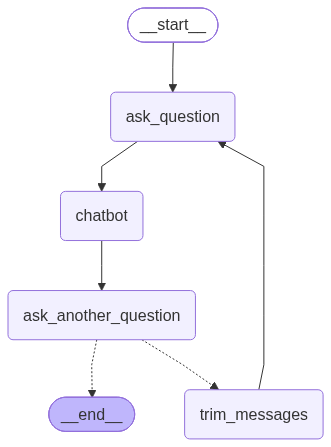

In [24]:
graph_compiled

#### Test the Graph

In [27]:
graph_compiled.invoke(MessagesState(messages = []))


------> ENTERING ask_question:
What is your question?


 Who played in FIFA World Cup final 1986?



------> ENTERING chatbot:
================================== Ai Message ==================================

What is your question?
================================ Human Message =================================

Who played in FIFA World Cup final 1986?
================================== Ai Message ==================================

The 1986 FIFA World Cup final was played between Argentina and West Germany. The match took place on June 29, 1986, at the Estadio Azteca in Mexico City, Mexico. Argentina won the match 3-2, securing their second World Cup title.

------> ENTERING ask_another_question:
================================== Ai Message ==================================

What is your question?
================================ Human Message =================================

Who played in FIFA World Cup final 1986?
================================== Ai Message ==================================

The 1986 FIFA World Cup final was played between Argentina and West Germany. The ma

 yes



------> ENTERING trim_messages:

------> ENTERING ask_question:
================================== Ai Message ==================================

What is your question?
================================ Human Message =================================

Who played in FIFA World Cup final 1986?
================================== Ai Message ==================================

The 1986 FIFA World Cup final was played between Argentina and West Germany. The match took place on June 29, 1986, at the Estadio Azteca in Mexico City, Mexico. Argentina won the match 3-2, securing their second World Cup title.
================================== Ai Message ==================================

Would you like to ask one more question (yes/no)
================================ Human Message =================================

yes
What is your question?


 What about 1950?


... (15 outputs left out)

 What was the first world cup that I aksed you about?



------> ENTERING chatbot:
================================== Ai Message ==================================

What is your question?
================================ Human Message =================================

1938?
================================== Ai Message ==================================

The 1938 FIFA World Cup was the third edition of the World Cup, held in France from June 4 to June 19, 1938. It was the last World Cup before World War II and the first to be held in a single country in Europe. 

A total of 15 teams participated in the tournament, as Austria, which had qualified, was annexed by Germany and thus withdrew. The tournament followed a knockout format, starting from the round of 16.

Italy successfully
================================== Ai Message ==================================

Would you like to ask one more question (yes/no)
================================ Human Message =================================

yes
================================== Ai Message =

 no


{'messages': [AIMessage(content='What is your question?', additional_kwargs={}, response_metadata={}, id='8282c73e-7e4e-4fda-9a27-bbd2863edfd0', tool_calls=[], invalid_tool_calls=[]),
  HumanMessage(content='1938?', additional_kwargs={}, response_metadata={}, id='cc5b85fc-3cb7-42c1-9f13-52e09f1f40b2'),
  AIMessage(content='The 1938 FIFA World Cup was the third edition of the World Cup, held in France from June 4 to June 19, 1938. It was the last World Cup before World War II and the first to be held in a single country in Europe. \n\nA total of 15 teams participated in the tournament, as Austria, which had qualified, was annexed by Germany and thus withdrew. The tournament followed a knockout format, starting from the round of 16.\n\nItaly successfully', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 100, 'prompt_tokens': 160, 'total_tokens': 260, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_t